# CV train DL

Стартовый блокнот для экспериментов по компьютерному зрению.

In [3]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
import torch.nn.init as init

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"numpy {np.__version__}")
print(f"pandas {pd.__version__}")
print(f"sklearn {sklearn.__version__}")
print(f"torch {torch.__version__}, device: {device}")

numpy 2.5.3
pandas 3.0.6
sklearn 1.9.1
torch 2.14.0, device: cpu


In [ ]:
class TwoLayerNet(nn.Module):
    def __init__(self, n_input, n_hidden, n_output):
        super().__init__()
        self.fc1 = nn.Linear(n_input, n_hidden)
        self.fc2 = nn.Linear(n_hidden, n_output)
        self.dropout = nn.Dropout(p=0.5)
        self.bn1 = nn.BatchNorm1d(16)
        self.maxpool = nn.MaxPool2d(2, stride=2)
    
    def forward(self, x):
        z1 = self.fc1(x)
        z1 = self.bn1(z1)
        z1 = self.
        h1 = torch.relu(z1)
        h1 = self.dropout(h1)
        z2 = self.fc2(h1)
        y_hat = torch.sigmoid(z2)
        return y_hat

In [3]:
def init_kaiming(m):
    if isinstance(m, nn.Linear):
        init.kaiming_uniform_(m.weight)
        init.zeros_(m.bias)


In [4]:
from sklearn.datasets import make_moons

In [5]:
X, y = make_moons(n_samples=300, noise=0.1, random_state=777)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=777)

In [6]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

In [7]:
print(X_train_tensor.shape)  # ожидаем (N_train, 2)
print(X_test_tensor.shape)   # ожидаем (N_test, 2)
print(y_train_tensor.shape)  # ожидаем (N_train, 1)
print(y_test_tensor.shape)   # ожидаем (N_test, 1)

torch.Size([240, 2])
torch.Size([60, 2])
torch.Size([240])
torch.Size([60])


In [8]:
y_train_tensor = y_train_tensor.reshape(-1, 1)
y_test_tensor = y_test_tensor.reshape(-1, 1)

In [9]:
model = TwoLayerNet(2, 16, 1)
model.apply(init_kaiming)

loss_fn = nn.BCELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
n_epochs = 5000
batch_size = 16
N = len(X_train_tensor)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

for epoch in range(n_epochs):
    model.train()
    epoch_loss=0.0
    n_batches = 0
    for i in range(0, N, batch_size):
        X_batch = X_train_tensor[i:i+batch_size]
        y_batch = y_train_tensor[i:i+batch_size]
        
        optimizer.zero_grad()
        y_hat = model(X_batch)
        loss = loss_fn(y_hat, y_batch)
        loss.backward()
        optimizer.step()

        n_batches += 1
        epoch_loss += loss.item()
        

    model.eval()
    with torch.no_grad():
        y_train_pred = model(X_train_tensor)
        train_loss = loss_fn(y_train_pred, y_train_tensor)
        y_test_pred = model(X_test_tensor)
        test_loss = loss_fn(y_test_pred, y_test_tensor)

    scheduler.step()
    current_lr = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch}: lr={current_lr:.6f}")
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: train_loss={train_loss.item():.4f}, test_loss={test_loss.item():.4f}")
    

Epoch 0: lr=0.010000
Epoch 0: train_loss=0.4685, test_loss=0.3963
Epoch 1: lr=0.010000
Epoch 2: lr=0.010000
Epoch 3: lr=0.010000
Epoch 4: lr=0.010000
Epoch 5: lr=0.010000
Epoch 6: lr=0.010000
Epoch 7: lr=0.010000
Epoch 8: lr=0.010000
Epoch 9: lr=0.010000
Epoch 10: lr=0.010000
Epoch 10: train_loss=0.2516, test_loss=0.1823
Epoch 11: lr=0.010000
Epoch 12: lr=0.010000
Epoch 13: lr=0.010000
Epoch 14: lr=0.010000
Epoch 15: lr=0.010000
Epoch 16: lr=0.010000
Epoch 17: lr=0.010000
Epoch 18: lr=0.010000
Epoch 19: lr=0.010000
Epoch 20: lr=0.010000
Epoch 20: train_loss=0.2225, test_loss=0.1697
Epoch 21: lr=0.010000
Epoch 22: lr=0.009999
Epoch 23: lr=0.009999
Epoch 24: lr=0.009999
Epoch 25: lr=0.009999
Epoch 26: lr=0.009999
Epoch 27: lr=0.009999
Epoch 28: lr=0.009999
Epoch 29: lr=0.009999
Epoch 30: lr=0.009999
Epoch 30: train_loss=0.2047, test_loss=0.1556
Epoch 31: lr=0.009999
Epoch 32: lr=0.009999
Epoch 33: lr=0.009999
Epoch 34: lr=0.009999
Epoch 35: lr=0.009999
Epoch 36: lr=0.009999
Epoch 37: lr=

In [10]:
min_par0 = min(X_train_tensor[:, 0].min(), X_test_tensor[:, 0].min())
min_par1 = min(X_train_tensor[:, 1].min(), X_test_tensor[:, 1].min())
max_par0 = max(X_train_tensor[:, 0].max(), X_test_tensor[:, 0].max())
max_par1 = max(X_train_tensor[:, 1].max(), X_test_tensor[:, 1].max())

In [11]:
XX, YY = np.meshgrid(np.linspace(min_par0-1, max_par0+1, 100), np.linspace(min_par1-1, max_par1+1, 100))
grid_points = np.stack([XX.ravel(), YY.ravel()], axis=1)

In [12]:
with torch.no_grad():
    grid_points_tensor = torch.tensor(grid_points, dtype=torch.float32)
    grid_pred = model(grid_points_tensor)
grid_pred = grid_pred.squeeze()
grid_pred = grid_pred.reshape(100, 100)


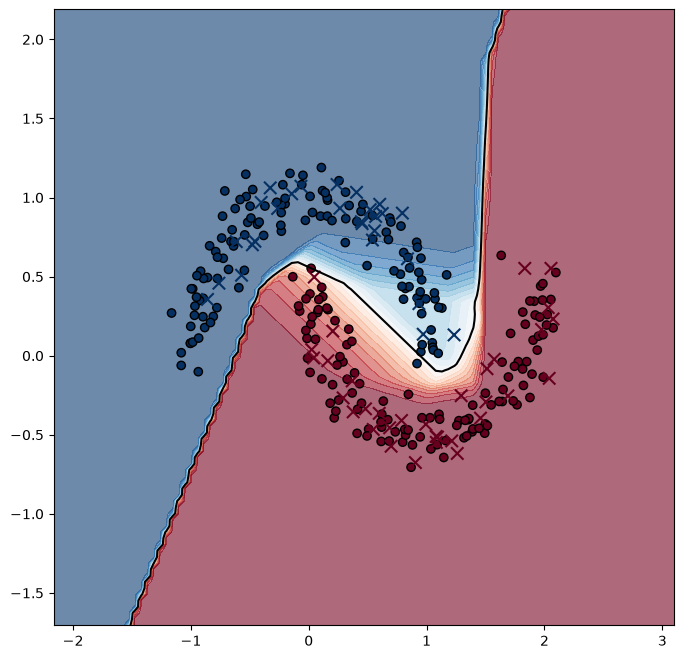

In [13]:
plt.figure(figsize=(8, 8))
plt.contourf(XX, YY, grid_pred, levels=20, cmap='RdBu_r', alpha=0.6)
plt.contour(XX, YY, grid_pred, levels=[0.5], colors='black')
plt.scatter(X_train_tensor[:, 0], X_train_tensor[:, 1], c=y_train_tensor, cmap='RdBu_r', edgecolors='k')
plt.scatter(X_test_tensor[:, 0], X_test_tensor[:, 1], c=y_test_tensor, cmap='RdBu_r', marker='x', s=80)

In [14]:
train_acc = ((y_train_pred > 0.5).float() == y_train_tensor).float().mean()
test_acc = ((y_test_pred > 0.5).float() == y_test_tensor).float().mean()
print(train_acc)
print(test_acc)

tensor(0.9958)
tensor(1.)


In [15]:
print(f"Epoch {epoch}: "
      f"epoch_loss={epoch_loss/n_batches:.4f}, "   # средний по батчам
      f"train_loss={train_loss.item():.4f}, "       # по всей train
      f"test_loss={test_loss.item():.4f}")          # по всей test

Epoch 4999: epoch_loss=0.1284, train_loss=0.0686, test_loss=0.0423
